In [43]:
# FactoryLens | Notebook 3 — Feature Engineering & ML Modeling

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, 
                             confusion_matrix, 
                             ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid", palette="muted")

# Load your enriched dataset
data_path = r"C:\Users\yashp\Downloads\MyFactoryLens\MyFactorylens_dataset.csv"
df = pd.read_csv(data_path)

print(f"✅ Enriched dataset loaded. Shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")

✅ Enriched dataset loaded. Shape: (10000, 18)

Columns: ['udi', 'product_id', 'product_type', 'air_temp_k', 'process_temp_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min', 'machine_failure', 'failure_twf', 'failure_hdf', 'failure_pwf', 'failure_osf', 'failure_rnf', 'shift', 'operator_experience', 'machine_age_category', 'maintenance_status']


In [44]:
# Cell 2 — Feature Engineering
# Creating 3 meaningful features from existing sensor data

# Feature 1: Mechanical Power (kW)
# Formula: Torque (Nm) × Speed (RPM) / 9549
# High power = machine working harder = more stress
df['power_kw'] = (df['torque_nm'] * df['rotational_speed_rpm']) / 9549

# Feature 2: Temperature Difference
# Process temp minus air temp
# Low diff = poor heat dissipation = failure risk (confirmed in EDA)
df['temp_diff'] = df['process_temp_k'] - df['air_temp_k']

# Feature 3: Tool Wear as ordered number
# Converts category text to number preserving risk order
wear_map = {
    'New': 0,
    'Mid-life': 1,
    'Aging': 2,
    'Critical': 3
}
df['tool_wear_category_num'] = df['machine_age_category'].map(wear_map)

# Verify
print("✅ Feature engineering complete.")
print("\nNew features added:")
print(df[['power_kw', 'temp_diff', 
          'tool_wear_category_num']].describe().round(2))

✅ Feature engineering complete.

New features added:
       power_kw  temp_diff  tool_wear_category_num
count  10000.00    10000.0                10000.00
mean       6.28       10.0                    0.87
std        1.07        1.0                    0.97
min        1.15        7.6                    0.00
25%        5.56        9.3                    0.00
50%        6.27        9.8                    1.00
75%        7.00       11.0                    2.00
max       10.47       12.1                    3.00


In [45]:
# Cell 3 — Prepare features and target for ML

# Step 1: Select columns to use as features
# Dropping: IDs, target, failure subtypes, 
# text-based derived columns, chart-only columns
features = [
    'air_temp_k',
    'process_temp_k', 
    'rotational_speed_rpm',
    'torque_nm',
    'tool_wear_min',
    'product_type',
    'shift',
    'operator_experience',
    'power_kw',
    'temp_diff',
    'tool_wear_category_num'
]

# Step 2: Create X and y
X = df[features].copy()
y = df['machine_failure']

# Step 3: Encode text columns using get_dummies
# This converts categories into 0/1 columns
X = pd.get_dummies(X, columns=['product_type', 
                                'shift', 
                                'operator_experience'])

print("✅ Features prepared.")
print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"\nFeature columns after encoding:")
print(X.columns.tolist())
print(f"\nClass distribution in target:")
print(y.value_counts())

✅ Features prepared.

X shape: (10000, 17)
y shape: (10000,)

Feature columns after encoding:
['air_temp_k', 'process_temp_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min', 'power_kw', 'temp_diff', 'tool_wear_category_num', 'product_type_H', 'product_type_L', 'product_type_M', 'shift_Evening', 'shift_Morning', 'shift_Night', 'operator_experience_Expert', 'operator_experience_Junior', 'operator_experience_Senior']

Class distribution in target:
machine_failure
0    9661
1     339
Name: count, dtype: int64


In [46]:
# Cell 4 — Train Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("✅ Data split complete.")
print(f"\nTraining set: {X_train.shape[0]} rows")
print(f"Test set:     {X_test.shape[0]} rows")
print(f"\nFailure rate in training: "
      f"{y_train.mean()*100:.2f}%")
print(f"Failure rate in test:     "
      f"{y_test.mean()*100:.2f}%")

✅ Data split complete.

Training set: 8000 rows
Test set:     2000 rows

Failure rate in training: 3.39%
Failure rate in test:     3.40%


In [47]:
# Cell 5 — Train and Compare Three Models

# Define all three models
models = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced',
        random_state=42,
        max_iter=1000
    ),
    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_estimators=100
    )
}

# Train each model and store results
results = {}

for model_name, model in models.items():
    # Train
    model.fit(X_train, y_train)
    
    # Predict on test set
    y_pred = model.predict(X_test)
    
    # Store predictions
    results[model_name] = y_pred
    
    print(f"\n{'='*45}")
    print(f"Model: {model_name}")
    print(f"{'='*45}")
    print(classification_report(y_test, y_pred, 
          target_names=['No Failure', 'Failure']))

print("\n✅ All three models trained and evaluated.")


Model: Logistic Regression
              precision    recall  f1-score   support

  No Failure       0.99      0.86      0.92      1932
     Failure       0.18      0.85      0.30        68

    accuracy                           0.86      2000
   macro avg       0.59      0.86      0.61      2000
weighted avg       0.97      0.86      0.90      2000


Model: Decision Tree
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.82      0.72      0.77        68

    accuracy                           0.98      2000
   macro avg       0.90      0.86      0.88      2000
weighted avg       0.98      0.98      0.98      2000


Model: Random Forest
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      1932
     Failure       0.93      0.62      0.74        68

    accuracy                           0.99      2000
   macro avg       0.96      0.81      0.87      2000
we

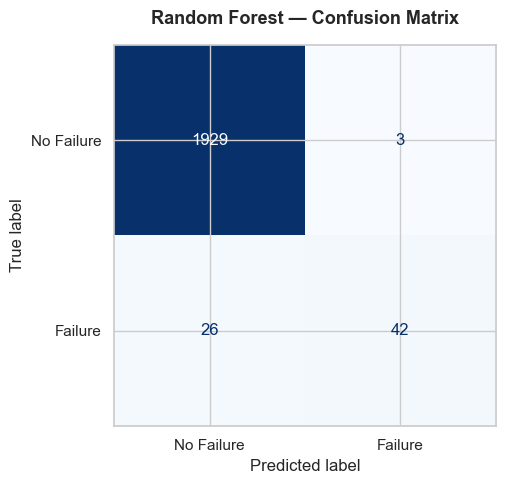

=== Confusion Matrix Breakdown ===
True Negatives  — Correctly said No Failure: 1929
False Positives — False alarms raised:       3
False Negatives — Failures missed:           26
True Positives  — Failures caught:           42

Out of 68 real failures:
  Caught:  42 (61.8%)
  Missed:  26 (38.2%)


In [48]:
# Cell 6 — Confusion Matrix for Random Forest

# Get Random Forest predictions
rf_predictions = results['Random Forest']

# Create confusion matrix
cm = confusion_matrix(y_test, rf_predictions)

# Display visually
fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Failure', 'Failure']
)

disp.plot(
    cmap='Blues',
    ax=ax,
    colorbar=False
)

ax.set_title("Random Forest — Confusion Matrix",
             fontsize=13, fontweight='bold', pad=15)

plt.tight_layout()
plt.savefig("chart7_confusion_matrix.png", dpi=150)
plt.show()

# Print breakdown in plain English
tn, fp, fn, tp = cm.ravel()

print(f"=== Confusion Matrix Breakdown ===")
print(f"True Negatives  — Correctly said No Failure: {tn}")
print(f"False Positives — False alarms raised:       {fp}")
print(f"False Negatives — Failures missed:           {fn}")
print(f"True Positives  — Failures caught:           {tp}")
print(f"\nOut of {tp + fn} real failures:")
print(f"  Caught:  {tp} ({tp/(tp+fn)*100:.1f}%)")
print(f"  Missed:  {fn} ({fn/(tp+fn)*100:.1f}%)")

In [51]:
# Cell 7 — SHAP Explainability

# Install shap if needed — run this once





import shap

# Step 1: Get your trained Random Forest model
rf_model = models['Random Forest']

# Step 2: Create SHAP explainer
# TreeExplainer is designed specifically for 
# tree-based models like Random Forest
explainer = shap.TreeExplainer(rf_model)

# Step 3: Calculate SHAP values for test set
# This is where SHAP analyses every prediction
print("Calculating SHAP values — this may take 30 seconds...")
shap_values = explainer.shap_values(X_test)

print("✅ SHAP values calculated.")
print(f"Shape of SHAP values: {shap_values.shape}")

Calculating SHAP values — this may take 30 seconds...
✅ SHAP values calculated.
Shape of SHAP values: (2000, 17, 2)


=== Feature Importance via SHAP ===
                   Feature  Mean SHAP Value
      rotational_speed_rpm         0.105145
                  power_kw         0.104623
                 torque_nm         0.091995
             tool_wear_min         0.065935
                 temp_diff         0.061466
                air_temp_k         0.032825
    tool_wear_category_num         0.027927
            process_temp_k         0.020430
            product_type_L         0.006438
            product_type_M         0.004150
operator_experience_Senior         0.003026
             shift_Morning         0.002653
operator_experience_Junior         0.002625
               shift_Night         0.002572
             shift_Evening         0.002465
operator_experience_Expert         0.002291
            product_type_H         0.002253


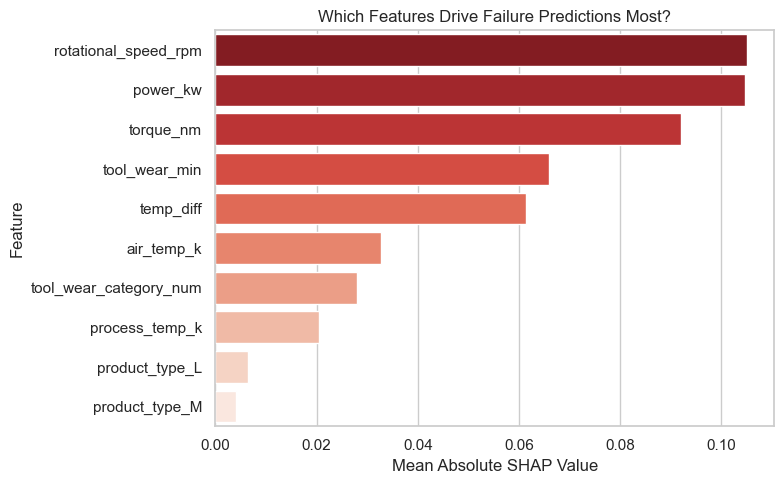

✅ SHAP chart done.


In [52]:
# Cell 8 — SHAP Global Feature Importance

# Extract SHAP values for Failure class (class 1)
shap_failure = shap_values[:, :, 1]

# Calculate mean absolute SHAP value per feature
# This tells us overall importance across all predictions
mean_shap = pd.DataFrame({
    'Feature': X_test.columns,
    'Mean SHAP Value': abs(shap_failure).mean(axis=0)
})

# Sort by importance
mean_shap = mean_shap.sort_values(
    'Mean SHAP Value',
    ascending=False
).reset_index(drop=True)

print("=== Feature Importance via SHAP ===")
print(mean_shap.to_string(index=False))

# Visualization — top 10 features only
top10 = mean_shap.head(10)

plt.figure(figsize=(8, 5))

sns.barplot(
    x='Mean SHAP Value',
    y='Feature',
    data=top10,
    hue='Feature',
    palette='Reds_r',
    legend=False
)

plt.title("Which Features Drive Failure Predictions Most?")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("chart8_shap_importance.png", dpi=150)
plt.show()

print("✅ SHAP chart done.")

In [53]:
# Cell 9 — Save trained Random Forest model

import joblib
import os

# Define save path
model_path = r"C:/Users/yashp/Downloads/MyFactoryLens/factorylens_model.pkl"

# Save the model
joblib.dump(models['Random Forest'], model_path)

print(f"✅ Model saved successfully.")
print(f"Location: {model_path}")

# Verify it saved by loading it back
loaded_model = joblib.load(model_path)
test_pred = loaded_model.predict(X_test)
print(f"\n✅ Model verified — loaded and predicted successfully.")
print(f"Predictions shape: {test_pred.shape}")

# Also save the feature column names
# Streamlit needs to know exact column order
feature_path = r"C:/Users/yashp/Downloads/MyFactoryLens/factorylens_features.pkl"
joblib.dump(X_test.columns.tolist(), feature_path)

print(f"\n✅ Feature names saved.")
print(f"Features: {X_test.columns.tolist()}")

✅ Model saved successfully.
Location: C:/Users/yashp/Downloads/MyFactoryLens/factorylens_model.pkl

✅ Model verified — loaded and predicted successfully.
Predictions shape: (2000,)

✅ Feature names saved.
Features: ['air_temp_k', 'process_temp_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min', 'power_kw', 'temp_diff', 'tool_wear_category_num', 'product_type_H', 'product_type_L', 'product_type_M', 'shift_Evening', 'shift_Morning', 'shift_Night', 'operator_experience_Expert', 'operator_experience_Junior', 'operator_experience_Senior']


## Notebook 3 Summary — Feature Engineering & ML Modeling

### Features Engineered
- power_kw: Torque × RPM / 9549 (mechanical power formula)
- temp_diff: Process temp minus air temp (thermal stress signal)
- tool_wear_category_num: Ordered encoding of machine age 
  category (0=New, 1=Mid-life, 2=Aging, 3=Critical)

### Model Comparison (Failure class metrics)
| Model | Precision | Recall | F1 |
|---|---|---|---|
| Logistic Regression | 0.18 | 0.85 | 0.30 |
| Decision Tree | 0.82 | 0.72 | 0.77 |
| Random Forest | 0.93 | 0.62 | 0.74 |

### Winner: Random Forest
Reason: Highest Precision (0.93) — only 3 false alarms 
out of 2000 test cases. Selected for SHAP explainability 
and operational credibility.

### Confusion Matrix (Random Forest)
- Real failures in test set: 68
- Caught: 42 (61.8%)
- Missed: 26 (38.2%)
- False alarms: 3

### SHAP Top 5 Features
1. rotational_speed_rpm
2. power_kw (engineered)
3. torque_nm
4. tool_wear_min
5. temp_diff (engineered)

### Files Saved
- factorylens_model.pkl — trained Random Forest
- factorylens_features.pkl — feature column names

### Next Step
Streamlit Dashboard — interactive prediction interface

In [54]:
import subprocess
subprocess.run(['pip', 'install', 'streamlit'], check=True)

CompletedProcess(args=['pip', 'install', 'streamlit'], returncode=0)